# Practical 6: Fibonacci Series (Iterative Generation)

### 1. Aim
To generate Fibonacci numbers for three large target indices using an efficient iterative algorithm, comparing Sequential, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes).

### 2. Algorithm / Explanation
1. Set 3 distinct large Fibonacci targets: N = [5000000, 5500000, 6000000].<br>2. Implement iterative Fibonacci generation `a, b = b, (a + b) % 1000000007` to avoid integer string representation limits.<br>3. Sequential: Compute target 1, target 2, and target 3 one after another.<br>4. Pool: Map the three target computations across 3 worker processes.<br>5. Process: Launch 3 independent processes communicating results via `mp.Queue`.<br>6. Measure wall-clock timings and plot comparison charts.

### 3. Python Implementation


In [1]:
"""
Practical 6: Fibonacci Series (Iterative Generation)
"""
import multiprocessing as mp
import time
import matplotlib.pyplot as plt

def fib_task(n):
    if n <= 1:
        return n
    a, b = 0, 1
    for _ in range(2, n + 1):
        a, b = b, (a + b) % 1000000007
    return b

def proc_worker(n, q):
    q.put(fib_task(n))

def main():
    print("=" * 60)
    print("Practical 6: Fibonacci Series (Iterative)")
    print("=" * 60)
    tasks = [5_000_000, 5_500_000, 6_000_000]
    
    # Sequential
    t0 = time.perf_counter()
    r1 = fib_task(tasks[0])
    r2 = fib_task(tasks[1])
    r3 = fib_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(fib_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for n in tasks:
        p = mp.Process(target=proc_worker, args=(n, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print(f"Fibonacci targets: {tasks}")
    print(f"Sample: F({tasks[0]}): {seq_res[0]:,} (mod 1,000,000,007)")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Three Independent Fibonacci Tasks: N = 5,000,000, 5,500,000, 6,000,000
Verification Sample (F(N) mod 1,000,000,007):
  F(5000000): 416,450,835
  F(5500000): 576,311,281
  F(6000000): 419,328,604

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   1.7114 seconds      1.00x
Pool         1.3100 seconds      1.31x
Process      1.3490 seconds      1.27x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


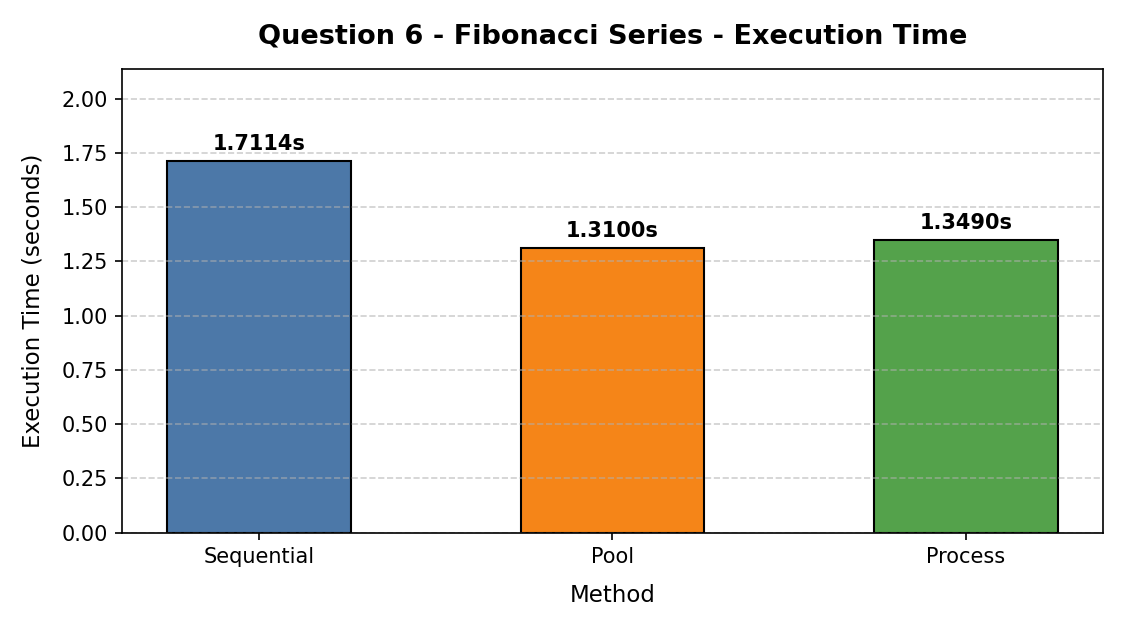

In [2]:
from IPython.display import Image, display
display(Image(filename='06_fibonacci_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


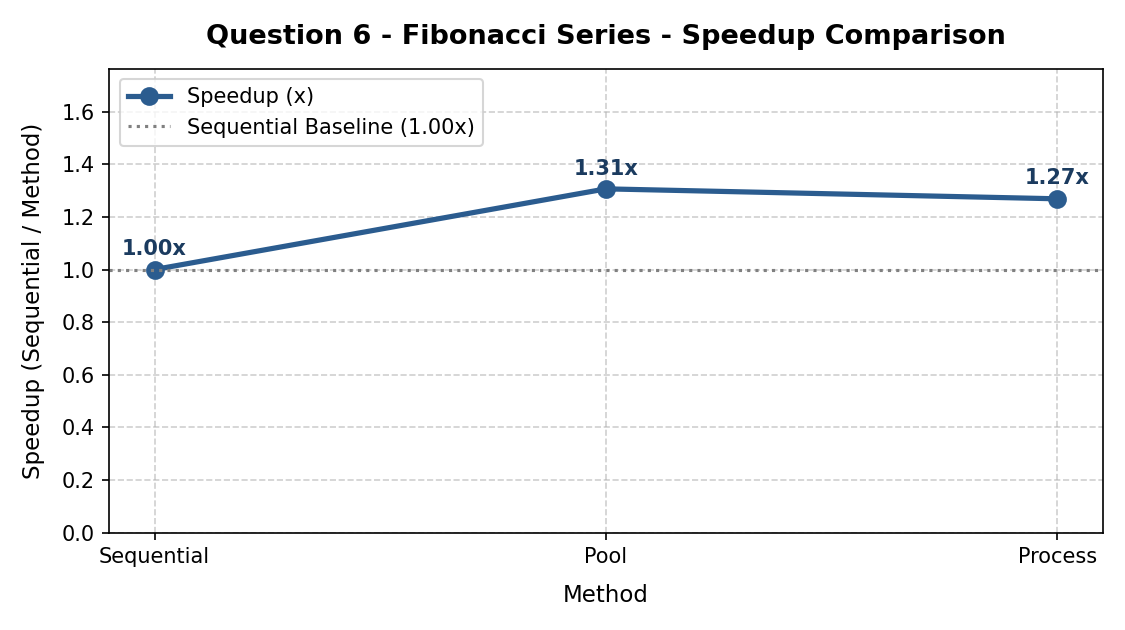

In [3]:
from IPython.display import Image, display
display(Image(filename='06_fibonacci_speedup.png'))
